# Robust regression

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import t
from ipywidgets import interact, FloatSlider

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
pi_color    = '#cfe8f3'
true_color  = '#333333'
ols_color   = '#E69F00'

## Data with outliers

We simulate 50 observations from a straight line, and move five of them down. We fit a quadratic model (the true coefficient of the quadratic term is zero).

In [3]:
alpha = 0.05
rng = np.random.default_rng(111)

n = 50
x = np.linspace(0, 20, n)
X = np.column_stack((x, (x-5)**2))
X = sm.add_constant(X)
p = X.shape[1]

sigma = 0.3   # smaller error variance makes OLS<->RLM contrast bigger
beta_true = [5, 0.5, 0]
Y_true = X @ beta_true
Y = Y_true + sigma*rng.normal(size=n)

outliers = [39, 41, 43, 45, 48]
Y[outliers] -= 5   # add some outliers (10% of the sample)

In [4]:
def plot_data(ax, legend=True):
    ax.plot(x, Y_true, '--', color=true_color, lw=1.5, label='True regression function')
    ax.plot(x, Y, 'o', color=point_color, markersize=6, markeredgecolor='white', markeredgewidth=0.5,
            label='Observed data')
    ax.plot(x[outliers], Y[outliers], 'o', markersize=12, markerfacecolor='none', markeredgecolor=true_color,
            markeredgewidth=1.2, label='Outliers')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.grid(True, alpha=0.25)
    if legend:
        ax.legend(loc='upper left', frameon=False)

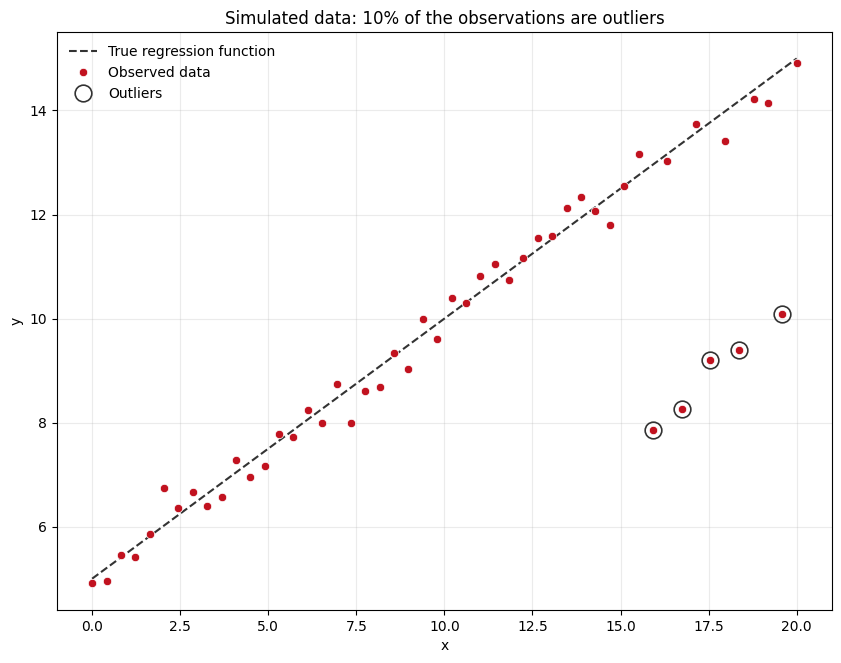

In [5]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_data(ax)
ax.set_title('Simulated data: 10% of the observations are outliers');

## Ordinary least squares

In [6]:
res_ols = sm.OLS(Y, X).fit()
print('Coefficients:', res_ols.params)
print('s2:          ', res_ols.scale)

Coefficients: [ 5.03341085  0.52463901 -0.01327978]
s2:           1.7065411687697436


In [7]:
ols_pred = res_ols.get_prediction(X).summary_frame(alpha=alpha)

## Robust regression (M-estimator)

Instead of the sum of squared residuals, the M-estimators minimize $\sum_i \rho(e_i/\hat\sigma)$, where $\rho$ grows slower than the square for large residuals. `sm.RLM` uses by default the function of Huber, and estimates the scale $\hat\sigma$ with the median absolute deviation of the residuals.

In [8]:
res_rlm = sm.RLM(Y, X).fit()
print('Coefficients:', res_rlm.params)
print('sigma:       ', res_rlm.scale)

Coefficients: [ 4.94955110e+00  5.15159889e-01 -3.82957048e-03]
sigma:        0.4229048089722963


Notice that `scale` is an estimator of $\sigma^2$ in `OLS`, but an estimator of $\sigma$ in `RLM`. The five outliers inflate the first one, while the second is much closer to the true value 0.3.

In [9]:
print('OLS, estimated sigma:', np.sqrt(res_ols.scale))
print('RLM, estimated sigma:', res_rlm.scale)

OLS, estimated sigma: 1.3063464964433225
RLM, estimated sigma: 0.4229048089722963


For the intervals of the robust fit we use the estimated covariance matrix of the coefficients, `bcov_scaled`.

In [10]:
var_mean = np.diag(X @ res_rlm.bcov_scaled @ X.T)
q_t = t.ppf(1-alpha/2, n-p)

rlm_ci_lower = res_rlm.fittedvalues - q_t*np.sqrt(var_mean)
rlm_ci_upper = res_rlm.fittedvalues + q_t*np.sqrt(var_mean)
rlm_pi_lower = res_rlm.fittedvalues - q_t*np.sqrt(res_rlm.scale**2 + var_mean)
rlm_pi_upper = res_rlm.fittedvalues + q_t*np.sqrt(res_rlm.scale**2 + var_mean)

## OLS vs robust regression

The outliers pull the least squares fit down and make its bands much wider. The robust fit stays on the true regression function.

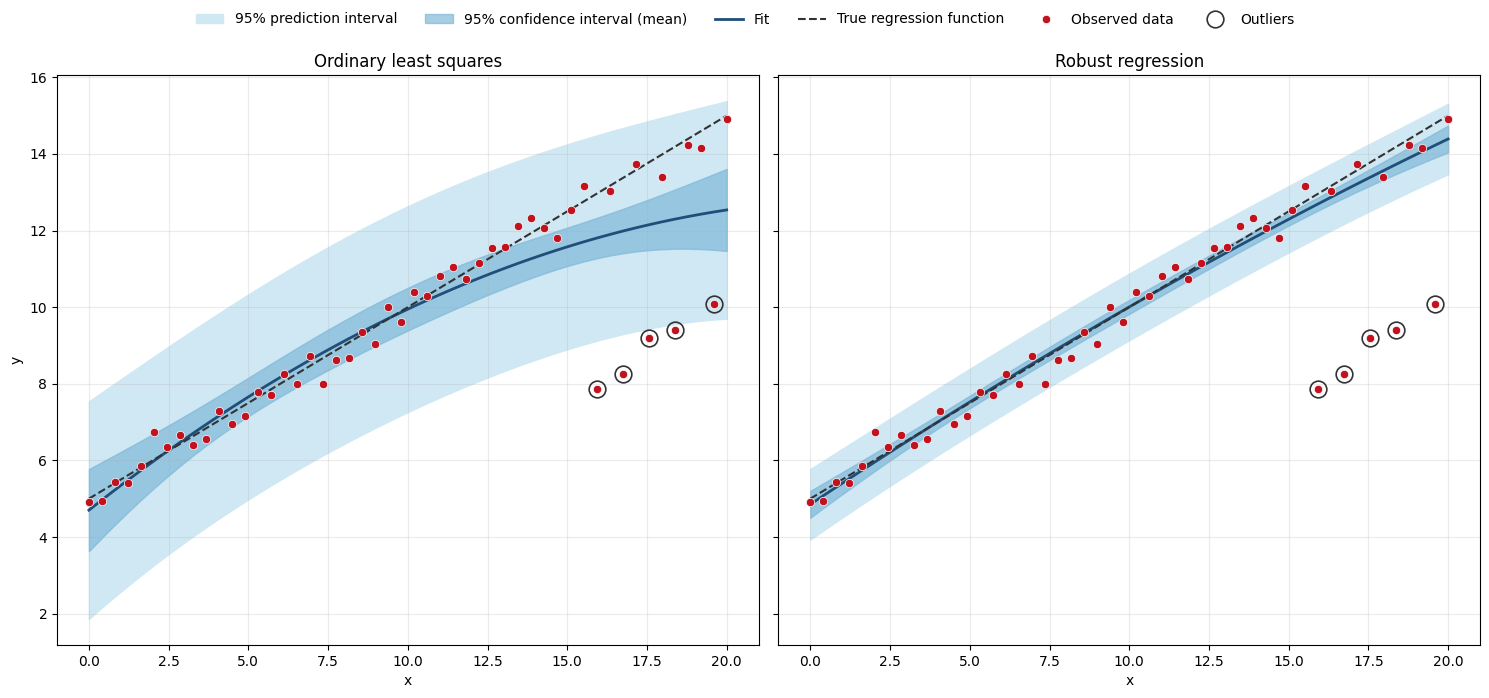

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'

fits = [(axes[0], 'Ordinary least squares', res_ols.fittedvalues, ols_pred['mean_ci_lower'], ols_pred['mean_ci_upper'],
         ols_pred['obs_ci_lower'], ols_pred['obs_ci_upper']),
        (axes[1], 'Robust regression', res_rlm.fittedvalues, rlm_ci_lower, rlm_ci_upper, rlm_pi_lower, rlm_pi_upper)]
for ax, name, fitted, ci_lower, ci_upper, pi_lower, pi_upper in fits:
    ax.fill_between(x, pi_lower, pi_upper, color=pi_color, label=pi_label)
    ax.fill_between(x, ci_lower, ci_upper, color=ci_color, alpha=0.7, label=ci_label)
    ax.plot(x, fitted, color=line_color, lw=2, label='Fit')
    plot_data(ax, legend=False)
    ax.set_title(name)
axes[1].set_ylabel('')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=6, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))

## Why it works: the loss functions

The function of Huber is quadratic for small residuals and linear for large ones, the constant $c$ sets the change (by default $c = 1.345$). The biweight of Tukey is constant for large residuals, so they have no effect at all. The robust fit is a weighted least squares fit with weights $w(e) = \psi(e)/e$, where $\psi = \rho'$.

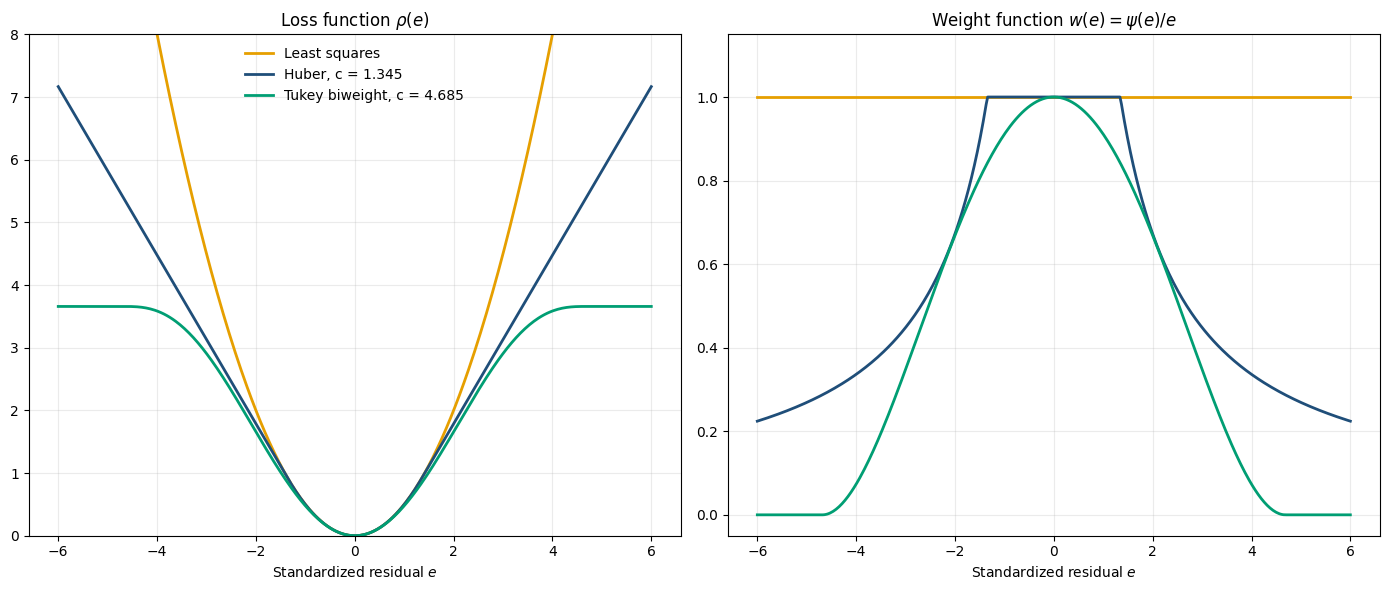

In [12]:
e_grid = np.linspace(-6, 6, 400)
norms = [('Least squares', sm.robust.norms.LeastSquares(), ols_color),
         ('Huber, c = 1.345', sm.robust.norms.HuberT(), line_color),
         ('Tukey biweight, c = 4.685', sm.robust.norms.TukeyBiweight(), '#009E73')]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name, norm, color in norms:
    axes[0].plot(e_grid, norm.rho(e_grid), color=color, lw=2, label=name)
    axes[1].plot(e_grid, norm.weights(e_grid), color=color, lw=2, label=name)
axes[0].set_ylim(0, 8)
axes[0].set_title(r'Loss function $\rho(e)$')
axes[1].set_title(r'Weight function $w(e) = \psi(e)/e$')
axes[1].set_ylim(-0.05, 1.15)
for ax in axes:
    ax.set_xlabel('Standardized residual $e$')
    ax.grid(True, alpha=0.25)
axes[0].legend(loc='upper center', frameon=False)
plt.tight_layout()

The weights of the last iteration show which observations the robust fit is ignoring.

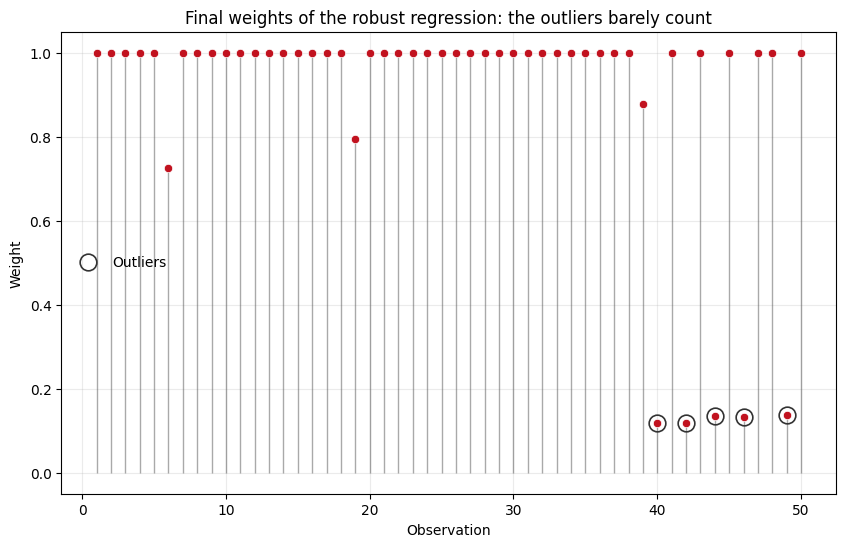

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
idx = np.arange(1, n+1)
ax.vlines(idx, 0, res_rlm.weights, color='#555555', lw=1, alpha=0.5)
ax.plot(idx, res_rlm.weights, 'o', color=point_color, markersize=6, markeredgecolor='white', markeredgewidth=0.5)
ax.plot(idx[outliers], res_rlm.weights[outliers], 'o', markersize=12, markerfacecolor='none',
        markeredgecolor=true_color, markeredgewidth=1.2, label='Outliers')
ax.set_xlabel('Observation')
ax.set_ylabel('Weight')
ax.set_title('Final weights of the robust regression: the outliers barely count')
ax.legend(loc='center left', frameon=False)
ax.grid(True, alpha=0.25)

## The tuning constant

With a large $c$ all the residuals are in the quadratic part, and the robust fit becomes least squares. Move the slider to change $c$ (this cell needs a running kernel).

In [ ]:
def plot_huber(ax, c, legend=True):
    res_c = sm.RLM(Y, X, M=sm.robust.norms.HuberT(t=c)).fit()
    ax.plot(x, res_ols.fittedvalues, color=ols_color, lw=2, label='Ordinary least squares')
    ax.plot(x, res_c.fittedvalues, color=line_color, lw=2, label='Robust regression (Huber)')
    plot_data(ax, legend)
    ax.set_title(f'c = {c:g}, mean weight of the outliers = {res_c.weights[outliers].mean():.2f}')

def interactive_huber(c):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    plot_huber(ax, c)
    plt.show()

interact(interactive_huber, c=FloatSlider(value=1.345, min=0.1, max=10, step=0.1, description='c'));

interactive(children=(FloatSlider(value=1.345, description='c', max=10.0, min=0.1), Output()), _dom_classes=('…

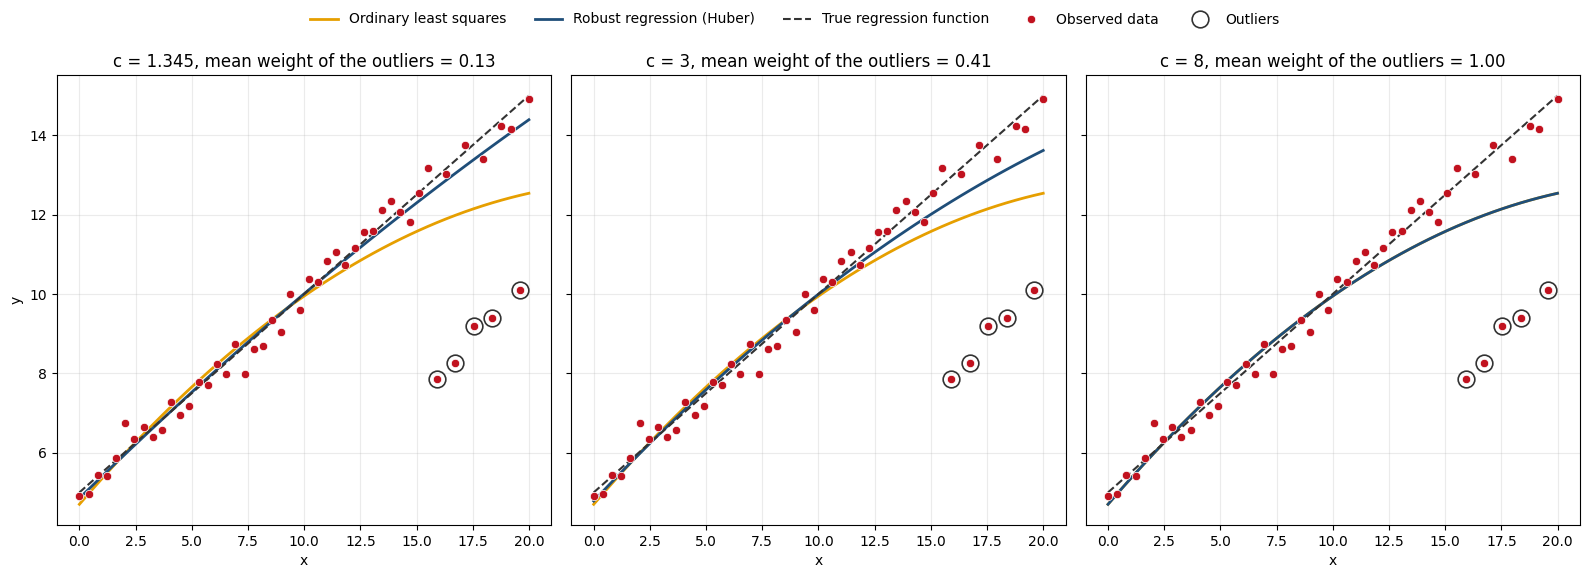

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.8), sharey=True)
for ax, c in zip(axes, [1.345, 3, 8]):
    plot_huber(ax, c, legend=False)
for ax in axes[1:]:
    ax.set_ylabel('')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))